# Proyecto - Asistente de IA para aerolínea

Ahora vamos a reunir lo que hemos aprendido para crear un asistente de IA de atención al cliente para una aerolínea

In [28]:
# imports

import os
import json
from dotenv import load_dotenv
from openai import OpenAI
import gradio as gr
import sqlite3

In [29]:
# Inicialización

load_dotenv(override=True)

google_api_key = os.getenv('GOOGLE_API_KEY')
if google_api_key:
    print(f"La clave de API de Google existe y comienza con {google_api_key[:8]}")
else:
    print("La clave de API de Google no está configurada")

MODEL = "gemini-3.1-flash-lite"
gemini = OpenAI(api_key=google_api_key, base_url="https://generativelanguage.googleapis.com/v1beta/openai/")

DB = "prices.db"

La clave de API de Google existe y comienza con AQ.Ab8RN


In [30]:
system_message = """
Eres un asistente útil para una aerolínea llamada FlightAI.
Da respuestas breves y amables, de no más de 1 oración.
Sé siempre preciso. Si no sabes la respuesta, dilo.
"""

In [31]:
def get_ticket_price(city):
    print(f"LLAMADA A LA HERRAMIENTA DE BASE DE DATOS: Obteniendo precio para {city}", flush=True)
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"El precio del boleto a {city} es ${result[0]}" if result else "No hay datos de precio disponibles para esta ciudad"

In [32]:
get_ticket_price("Paris")

LLAMADA A LA HERRAMIENTA DE BASE DE DATOS: Obteniendo precio para Paris


'El precio del boleto a Paris es $899.0'

In [33]:
price_function = {
    "name": "get_ticket_price",
    "description": "Obtiene el precio de un boleto de ida y vuelta a la ciudad de destino.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "La ciudad a la que el cliente quiere viajar",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}
tools = [{"type": "function", "function": price_function}]
tools

[{'type': 'function',
  'function': {'name': 'get_ticket_price',
   'description': 'Obtiene el precio de un boleto de ida y vuelta a la ciudad de destino.',
   'parameters': {'type': 'object',
    'properties': {'destination_city': {'type': 'string',
      'description': 'La ciudad a la que el cliente quiere viajar'}},
    'required': ['destination_city'],
    'additionalProperties': False}}}]

In [34]:
def chat(message, history):
    history = [{"role": h["role"], "content": h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages)
    return response.choices[0].message.content

gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7868
* To create a public link, set `share=True` in `launch()`.


In [35]:
def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses = handle_tool_calls(message)
        messages.append(message)
        messages.extend(responses)
        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    
    return response.choices[0].message.content

In [36]:
def handle_tool_calls(message):
    responses = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses

In [37]:
def chat(message, history):
    return "plátanos"

gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7869
* To create a public link, set `share=True` in `launch()`.


In [38]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7870
* To create a public link, set `share=True` in `launch()`.


## Un poco más sobre lo que hace Gradio:

1. Gradio construye una aplicación de frontend en Svelte a partir de nuestra descripción en Python de la interfaz
2. Gradio inicia un servidor basado en el framework web Starlette, que escucha en un puerto libre y sirve esta aplicación Svelte
3. Gradio crea rutas de backend para nuestros callbacks, como chat(), que llaman a nuestras funciones

Y, por supuesto, al generar la aplicación de frontend, Gradio se asegura de que el botón de enviar llame a la ruta de backend correcta.

¡Eso es todo!

Es simple, y el resultado se siente mágico.

# ¡Vamos a lo multimodal!

Podemos generar imágenes localmente con Stable Diffusion 1.5. Es gratis, pero usa la GPU de tu equipo.

Vamos a poner esto en una función llamada artist.

### Aviso: la primera carga del modelo tarda unos segundos y cada imagen unos 20 segundos en una GTX 1660 Ti. Las imágenes son de 512×512.

In [39]:
# Algunos imports para manejar imágenes

import base64 #Convierte texto base64 en bytes y viceversa
from io import BytesIO #trata bytes en memoria como un archivo
from PIL import Image #La librería Pillow permite manipular imágenes

In [40]:
# Generación local con Stable Diffusion 1.5 (gratis, usa tu GPU)
# Se usa fp32: en fp16 la GTX 1660 Ti genera imágenes completamente negras
import torch
from diffusers import StableDiffusionPipeline

sd_pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float32,
    safety_checker=None,   # desactivado para ahorrar descarga y memoria en esta práctica
    feature_extractor=None,
)
sd_pipe.enable_attention_slicing()
sd_pipe.to("cuda")

def artist(city):
    image = sd_pipe(
        f"An image representing a vacation in {city}, showing tourist spots and everything unique about {city}, in a vibrant pop-art style",
        height=512,
        width=512,
        num_inference_steps=25,
        guidance_scale=7.5,
    ).images[0]
    return image

c:\Users\ricky\ml-env\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 5/5 [00:04<00:00,  1.06it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


100%|██████████| 25/25 [00:15<00:00,  1.62it/s]


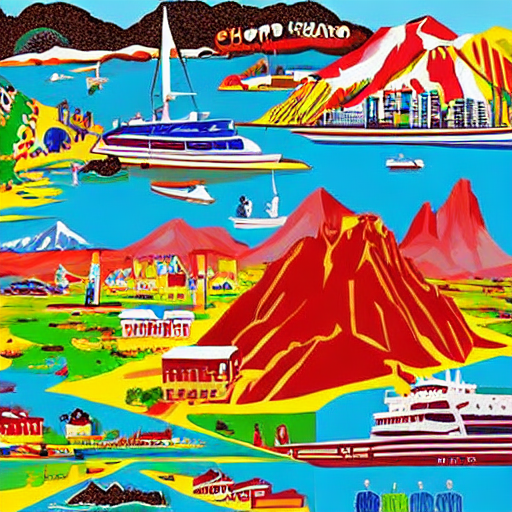

In [41]:
image = artist("Chile")
display(image)

In [42]:
# La compatibilidad con OpenAI no incluye TTS, así que usamos el SDK nativo de Google
from google import genai
from google.genai import types
import numpy as np
import io
import wave

gemini_audio = genai.Client(api_key=google_api_key)

def talker(message):
    response = gemini_audio.models.generate_content(
        model="gemini-3.8-flash-tts",
        contents=message,
        config=types.GenerateContentConfig(
            response_modalities=["AUDIO"],
            speech_config=types.SpeechConfig(
                voice_config=types.VoiceConfig(
                    prebuilt_voice_config=types.PrebuiltVoiceConfig(voice_name="Kore")  # Prueba también con Puck, Zephyr o Charon
                )
            ),
        ),
    )
    data = response.candidates[0].content.parts[0].inline_data.data
    if data[:4] == b"RIFF":                       # WAV con encabezado (3.8 por defecto)
        with wave.open(io.BytesIO(data), "rb") as w:
            return w.getframerate(), np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16)
    return 24000, np.frombuffer(data, dtype=np.int16)   # PCM crudo (modelos anteriores)

In [43]:
rate, samples = talker("Hola, este es un mensaje de prueba de FlightAI.")

print("frecuencia:", rate, "| tipo:", samples.dtype, "| muestras:", samples.shape)
print("duración (s):", round(len(samples) / rate, 2))

from IPython.display import Audio
Audio(samples, rate=rate)     # aparece un reproductor en la celda: dale play

frecuencia: 24000 | tipo: int16 | muestras: (88320,)
duración (s): 3.68


## Juntemos todo:

1. Un asistente de IA multimodal con generación de imágenes y audio
2. Llamadas a herramientas con consulta a una base de datos
3. Un paso hacia un flujo de trabajo agéntico

In [44]:
def chat(history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history
    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    cities = []
    image = None

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses, cities = handle_tool_calls_and_return_cities(message)
        messages.append(message)
        messages.extend(responses)
        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    reply = response.choices[0].message.content
    history += [{"role":"assistant", "content":reply}]

    voice = talker(reply)

    if cities:
        image = artist(cities[0])
    
    return history, voice, image

In [45]:
def handle_tool_calls_and_return_cities(message):
    responses = []
    cities = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            cities.append(city)
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses, cities

## Los 3 tipos de interfaz de Gradio

`gr.Interface` sirve para interfaces estándar y sencillas

`gr.ChatInterface` sirve para interfaces de chatbot estándar

`gr.Blocks` sirve para interfaces personalizadas donde controlas los componentes y los callbacks

In [46]:
# Callbacks (junto con la función chat() de arriba)

def put_message_in_chatbot(message, history):
        return "", history + [{"role":"user", "content":message}]

# Definición de la interfaz

with gr.Blocks() as ui:
    with gr.Row():
        chatbot = gr.Chatbot(height=500, type="messages")
        image_output = gr.Image(height=500, interactive=False)
    with gr.Row():
        audio_output = gr.Audio(autoplay=True)
    with gr.Row():
        message = gr.Textbox(label="Chatea con nuestro asistente de IA:")

# Conectando eventos a callbacks

    message.submit(put_message_in_chatbot, inputs=[message, chatbot], outputs=[message, chatbot]).then(
        chat, inputs=chatbot, outputs=[chatbot, audio_output, image_output]
    )

ui.launch(inbrowser=True, auth=("ed", "bananas"))

C:\Users\ricky\AppData\Local\Temp\ipykernel_27820\2238119788.py:10: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chatbot = gr.Chatbot(height=500, type="messages")


* Running on local URL:  http://127.0.0.1:7871
* To create a public link, set `share=True` in `launch()`.


# Ejercicios y aplicaciones de negocio

Añade más herramientas, por ejemplo para simular la reserva real de un vuelo. Un estudiante ya lo hizo y dejó su ejemplo en la carpeta de contribuciones de la comunidad.

Siguiente paso: aplica esto a tu negocio. Crea un asistente de IA multimodal con herramientas que puedan realizar una actividad de tu trabajo. ¿Un asistente de atención al cliente? ¿Un asistente para el onboarding de nuevos empleados? ¡Hay muchísimas posibilidades! Además, mira el ejercicio de fin de semana de la semana 2 en el notebook aparte.

<table style="margin: 0; text-align: left;">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/thankyou.jpg" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#090;">Una petición especial</h2>
            <span style="color:#090;">
                Mi editor me dice que hace una GRAN diferencia cuando los estudiantes califican este curso en Udemy: es una de las principales formas en que Udemy decide si lo muestra a otras personas. Si puedes tomarte un minuto para calificarlo, te lo agradecería muchísimo. Y, pase lo que pase, escríbeme a ed@edwarddonner.com si puedo ayudarte en algo.
            </span>
        </td>
    </tr>
</table>

In [1]:
import os, re, time
import xml.etree.ElementTree as ET                       # ← NUEVO
from dotenv import load_dotenv
from openai import OpenAI
from IPython.display import SVG, display

load_dotenv(override=True)
gemini = OpenAI(api_key=os.getenv("GOOGLE_API_KEY"),
                base_url="https://generativelanguage.googleapis.com/v1beta/openai/")

challenge = "un panda patinando al trabajo"      # cámbialo por el tuyo
prompt = f"Genera un SVG de este reto: {challenge}. Responde solo con el SVG."

In [2]:
def artist(model):
    inicio = time.time()
    response = gemini.chat.completions.create(model=model, messages=[{"role": "user", "content": prompt}])
    return response.choices[0].message.content, round(time.time() - inicio, 1)

def extraer_svg(texto):
    m = re.search(r"<svg.*?</svg>", texto, re.DOTALL)
    return m.group(0) if m else None

def tag(el):
    return el.tag.split("}", 1)[-1]

def reveal(svg, paso=0.15):
    if not svg:
        print("No devolvió un SVG")
        return
    ET.register_namespace("", "http://www.w3.org/2000/svg")
    try:
        root = ET.fromstring(svg)
    except ET.ParseError as error:
        print("El SVG viene mal formado y no se puede mostrar:", error)
        return

    drawable = {"path", "line", "ellipse", "rect", "polygon", "polyline", "circle"}
    style = ET.SubElement(root, "style")
    style.text = """
    @keyframes reveal { from { opacity: 0; } to { opacity: 1; } }
    .reveal { opacity: 0; animation: reveal 0.002s linear forwards; }
    """

    delay = 0.0
    for el in root.iter():
        if tag(el) in drawable:
            existing = el.get("style", "")
            el.set("style", f"{existing};animation-delay:{delay:.2f}s")
            el.set("class", (el.get("class", "") + " reveal").strip())
            delay += paso

    display(SVG(ET.tostring(root, encoding="unicode")))

tardó: 4.8 s


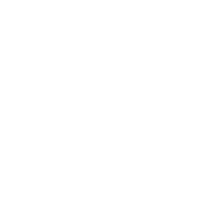

In [3]:
texto, segundos = artist("gemini-3.1-flash-lite")
svg = extraer_svg(texto)

print("tardó:", segundos, "s")
reveal(svg)                                              # ← en vez de display(SVG(svg))
if svg:
    open("panda.svg", "w", encoding="utf-8").write(svg)   # guarda el SVG original, sin animación

In [4]:
for m in gemini.models.list():
    print(m.id)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

--- gemini-3.1-flash-lite (2.1 s) ---


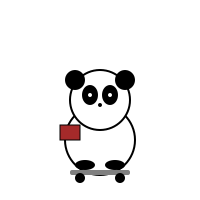

--- gemini-3.5-flash-lite (11.1 s) ---


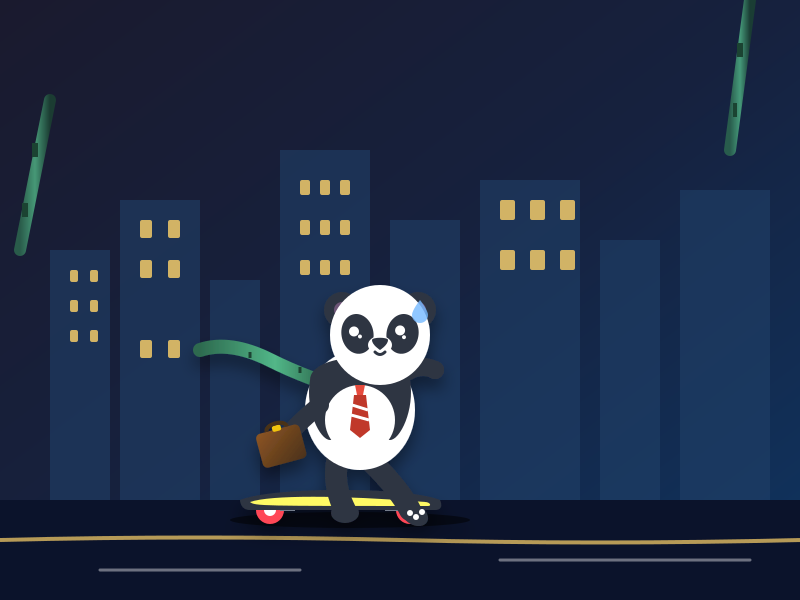

In [5]:
modelos = ["gemini-3.1-flash-lite", "gemini-3.5-flash-lite"]    # reemplaza el segundo

for modelo in modelos:
    texto, segundos = artist(modelo)
    svg = extraer_svg(texto)
    print(f"--- {modelo} ({segundos} s) ---")
    display(SVG(svg)) if svg else print("No devolvió un SVG")